# 03 · DBSCAN Clustering

DBSCAN (**D**ensity-**B**ased **S**patial **C**lustering of **A**pplications
with **N**oise) groups points that have at least `min_samples` neighbours within
a radius `eps`. Points in low-density areas become **noise** (label `-1`), and
the number of clusters is discovered rather than chosen.

- **`eps`** — neighbourhood radius in the *scaled* feature space. Too small:
  almost everything is noise. Too large: separate hotspots merge into one.
- **`min_samples`** — how many neighbours a point needs to be a dense core
  point. Larger values produce fewer, more robust clusters and more noise.

The workflow below is: k-distance graph → parameter grid → justified choice →
interpretation on the map.

In [1]:
%matplotlib inline

import os
import sys
from pathlib import Path

# Avoid a noisy joblib CPU-detection warning on Windows.
os.environ.setdefault("LOKY_MAX_CPU_COUNT", "4")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Locate the project root (the folder that contains src/) so the notebooks run
# whether Jupyter was started from notebooks/ or from the project root.
ROOT = Path.cwd()
while not (ROOT / "src").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

import preprocessing as pp
import clustering as cl
import visualization as viz

viz.set_style()
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 170)

print("Project root:", ROOT)
print("Dataset:", pp.DATA_PATH)

Project root: D:\proj\Real-Estate-Spatial-Price-Clustering\real-estate-clustering
Dataset: D:\proj\Real-Estate-Spatial-Price-Clustering\real-estate-clustering\data\housing.csv


## Part A — DBSCAN with geographical **and** housing features (11-D)

This is the literal configuration requested: every selected feature, scaled.

In [2]:
ds_combined = pp.prepare_dataset("geo_housing")
print(ds_combined)
print("feature matrix:", ds_combined.X.shape)

Dataset(feature_set='geo_housing', rows=20640, features=11)
feature matrix: (20640, 11)


### Choosing `eps` from a k-distance graph

For each point we plot the distance to its 5th nearest neighbour, sorted from
smallest to largest. The **knee** of this curve is a data-driven `eps` hint:
below it, points are in dense neighbourhoods; above it, the curve rises steeply
into sparse territory.

knee eps hint: 1.700
quantiles: {0.5: 0.706, 0.9: 1.154, 0.95: 1.394, 0.99: 2.098}
saved: D:\proj\Real-Estate-Spatial-Price-Clustering\real-estate-clustering\outputs\visualizations\k_distance_combined.png


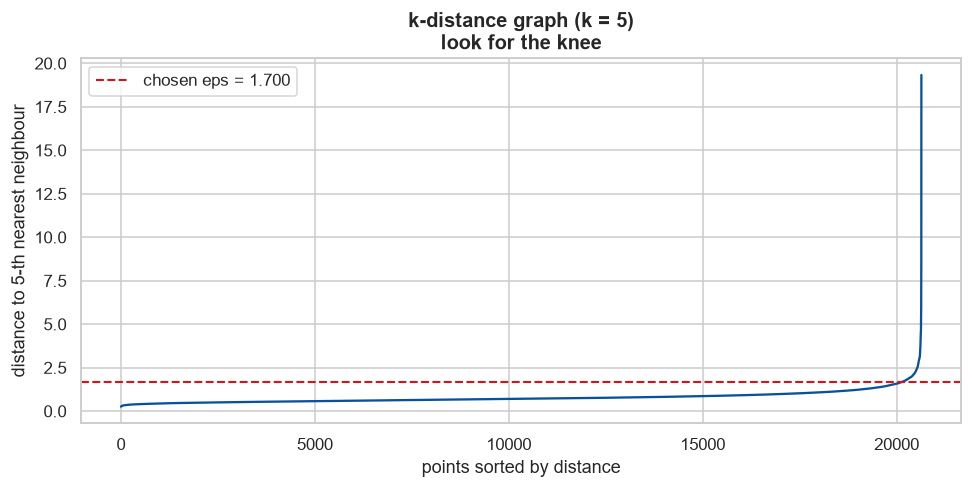

In [3]:
K = 5
kdist_combined = cl.k_distances(ds_combined.X, k=K)
knee_combined = cl.knee_point(kdist_combined)

print(f"knee eps hint: {knee_combined:.3f}")
print("quantiles:", pd.Series(kdist_combined).quantile([0.5, 0.9, 0.95, 0.99]).round(3).to_dict())

fig, path = viz.plot_k_distance(kdist_combined, k=K, eps=knee_combined,
                                name="k_distance_combined")
print("saved:", path)
plt.show()

### Parameter grid

The knee is only a hint, so a grid around it is evaluated. Every row below is a
real fit; `noise_pct`, cluster counts and silhouette come from those fits.

In [4]:
grid_combined = cl.dbscan_grid(
    ds_combined.X,
    eps_values=[0.9, 1.1, 1.3, 1.6, 1.8, 2.0],
    min_samples_values=[5, 10, 20, 30],
    sample_size=5000,
)
grid_combined.to_csv(pp.OUTPUT_DIR / "dbscan_combined_grid.csv", index=False)

grid_combined[["eps", "min_samples", "n_clusters", "n_noise", "noise_pct",
               "silhouette", "runtime_s"]].round(3)

,eps,min_samples,n_clusters,n_noise,noise_pct,silhouette,runtime_s
0,0.9,5,20,2721,13.18,0.072,2.203
1,0.9,10,8,3757,18.20,0.086,2.210
2,0.9,20,2,5448,26.40,0.344,2.239
3,0.9,30,1,6836,33.12,NaN,2.211
4,1.1,5,10,1269,6.15,0.145,2.997
5,1.1,10,4,1785,8.65,0.216,3.031
6,1.1,20,3,2483,12.03,0.265,3.175
7,1.1,30,2,3091,14.98,0.293,2.963
8,1.3,5,4,653,3.16,0.200,3.845
9,1.3,10,3,905,4.38,0.244,3.908


Reading the grid: at `eps=1.6, min_samples=5` there are 3 clusters and 1.31%
noise; increasing `min_samples` to 10 collapses to a single cluster. At
`eps=1.8` only 2 clusters remain. `eps=1.6` is the last setting before the
solution degenerates, so it is used to inspect what DBSCAN actually found.

In [5]:
eps_combined, ms_combined = 1.6, 5
labels_combined = cl.run_dbscan(ds_combined.X, eps=eps_combined, min_samples=ms_combined)

print(cl.label_summary(labels_combined))

combined_profile = cl.cluster_profile(ds_combined.df, labels_combined)
combined_profile[["n_points", "share_pct", "mean_house_value", "mean_income",
                  "mean_latitude", "mean_longitude",
                  "dominant_ocean_proximity"]].round(2)

{'n_clusters': 3, 'n_noise': 270, 'noise_pct': 1.31, 'n_clustered_points': 20370}


,n_points,share_pct,mean_house_value,mean_income,mean_latitude,mean_longitude,dominant_ocean_proximity
cluster,,,,,,,
0,20357,98.63,206441.44,3.86,35.63,-119.57,<1H OCEAN
1,8,0.04,210687.50,4.43,33.89,-117.82,<1H OCEAN
2,5,0.02,203280.00,4.51,38.20,-121.74,INLAND
-1,270,1.31,238051.23,4.69,35.79,-119.55,INLAND


saved: D:\proj\Real-Estate-Spatial-Price-Clustering\real-estate-clustering\outputs\visualizations\dbscan_clusters_combined.png


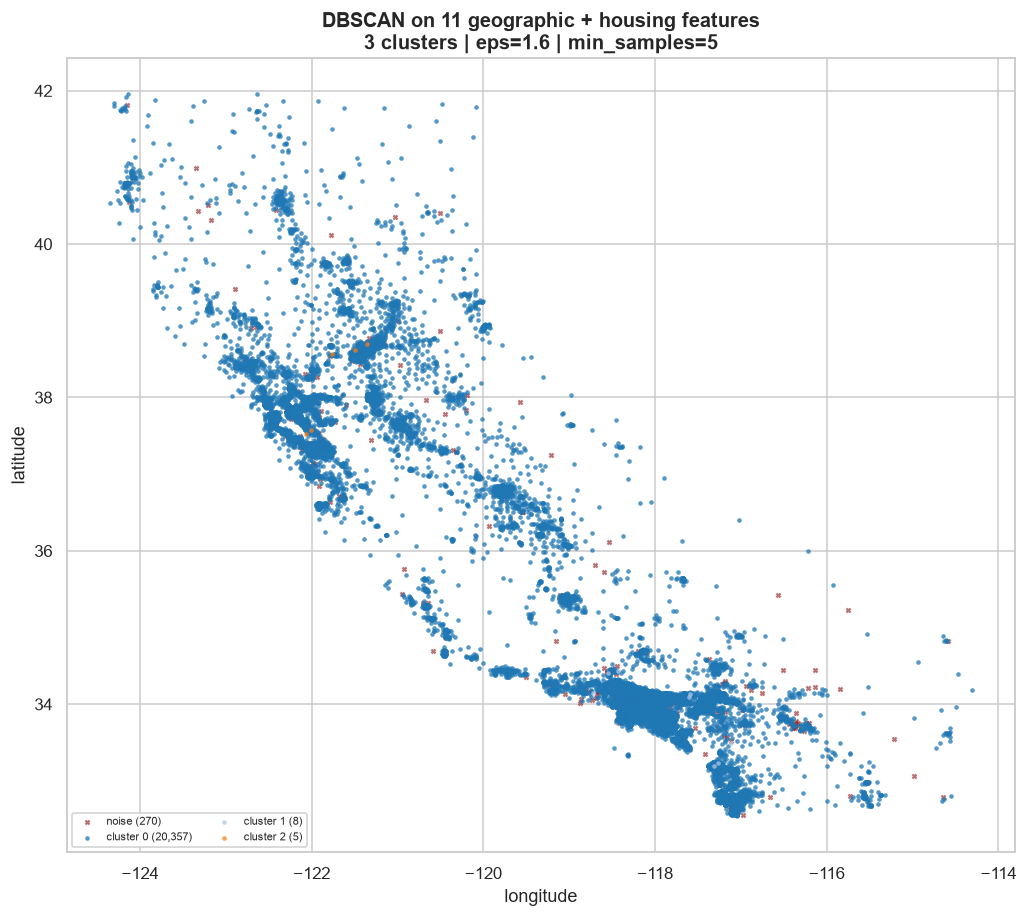

In [6]:
fig, path = viz.plot_dbscan_clusters(
    ds_combined.df, labels_combined, eps=eps_combined, min_samples=ms_combined,
    title="DBSCAN on 11 geographic + housing features",
    name="dbscan_clusters_combined",
)
print("saved:", path)
plt.show()

### Part A finding — the combined space is degenerate

**One cluster contains 20,357 of 20,640 block groups (98.63%).** The other two
"clusters" contain 8 and 5 points. This is not a hotspot segmentation; it is the
curse of dimensionality in action.

In 11 standardised dimensions, two block groups that are hundreds of kilometres
apart can still be very close in age, rooms, population, households and income.
With 9 attribute dimensions against 2 geographic ones, the density estimate is
dominated by attribute similarity, and almost the whole state forms one
connected dense region.

**Conclusion:** for DBSCAN to describe *geographical* hotspots, the feature
space must be primarily geographic. Part B does exactly that, and the shared
evaluation code keeps the comparison fair.

## Part B — DBSCAN on scaled geographical features (2-D)

Longitude and latitude are standardised like any other feature, so `eps` is in
standard-deviation units on each axis. Because the two axes have similar
standard deviations (2.00° and 2.14°), `eps` stays close to a distance in degrees.

knee eps hint: 0.038
quantiles: {0.5: 0.005, 0.9: 0.0221, 0.95: 0.0411, 0.99: 0.1098}
saved: D:\proj\Real-Estate-Spatial-Price-Clustering\real-estate-clustering\outputs\visualizations\k_distance_geo.png


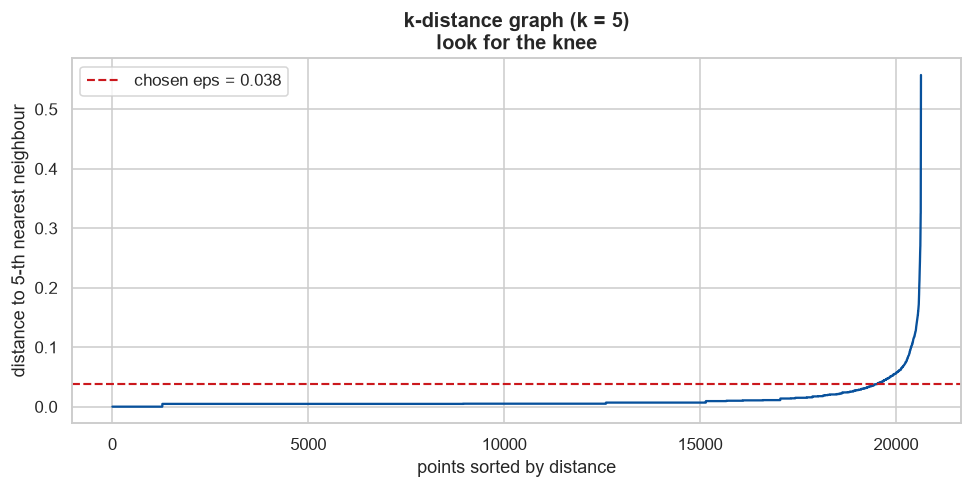

In [7]:
ds_geo = pp.prepare_dataset("geo")
kdist_geo = cl.k_distances(ds_geo.X, k=K)
knee_geo = cl.knee_point(kdist_geo)

print(f"knee eps hint: {knee_geo:.3f}")
print("quantiles:", pd.Series(kdist_geo).quantile([0.5, 0.9, 0.95, 0.99]).round(4).to_dict())

fig, path = viz.plot_k_distance(kdist_geo, k=K, eps=knee_geo, name="k_distance_geo")
print("saved:", path)
plt.show()

In [8]:
grid_geo = cl.dbscan_grid(
    ds_geo.X,
    eps_values=[0.03, 0.04, 0.05, 0.06, 0.07, 0.08, 0.10],
    min_samples_values=[10, 20, 30, 50],
    sample_size=8000,
)
grid_geo.to_csv(pp.OUTPUT_DIR / "dbscan_geo_grid.csv", index=False)

grid_geo[["eps", "min_samples", "n_clusters", "n_noise", "noise_pct",
          "silhouette", "davies_bouldin", "runtime_s"]].round(3)

,eps,min_samples,n_clusters,n_noise,noise_pct,silhouette,davies_bouldin,runtime_s
0,0.03,10,62,1507,7.30,0.256,0.419,0.152
1,0.03,20,50,2474,11.99,0.356,0.343,0.150
2,0.03,30,41,3172,15.37,0.365,0.321,0.152
3,0.03,50,28,4502,21.81,0.356,0.520,0.192
4,0.04,10,50,1078,5.22,0.293,0.475,0.178
5,0.04,20,40,1771,8.58,0.326,0.394,0.177
6,0.04,30,41,2279,11.04,0.374,0.404,0.178
7,0.04,50,21,3639,17.63,0.435,0.347,0.197
8,0.05,10,39,789,3.82,0.185,0.509,0.220
9,0.05,20,32,1227,5.94,0.366,0.453,0.221


saved: D:\proj\Real-Estate-Spatial-Price-Clustering\real-estate-clustering\outputs\visualizations\dbscan_grid_clusters.png


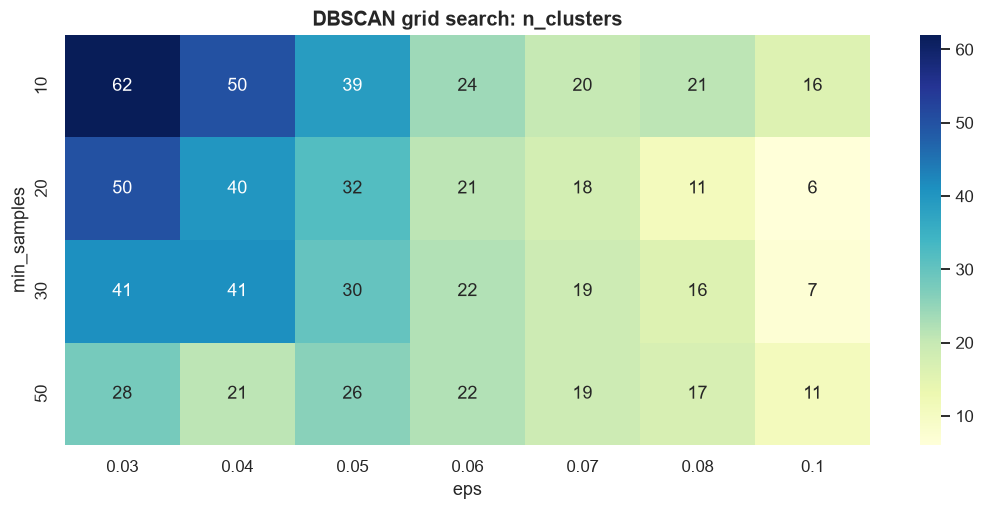

saved: D:\proj\Real-Estate-Spatial-Price-Clustering\real-estate-clustering\outputs\visualizations\dbscan_grid_silhouette.png


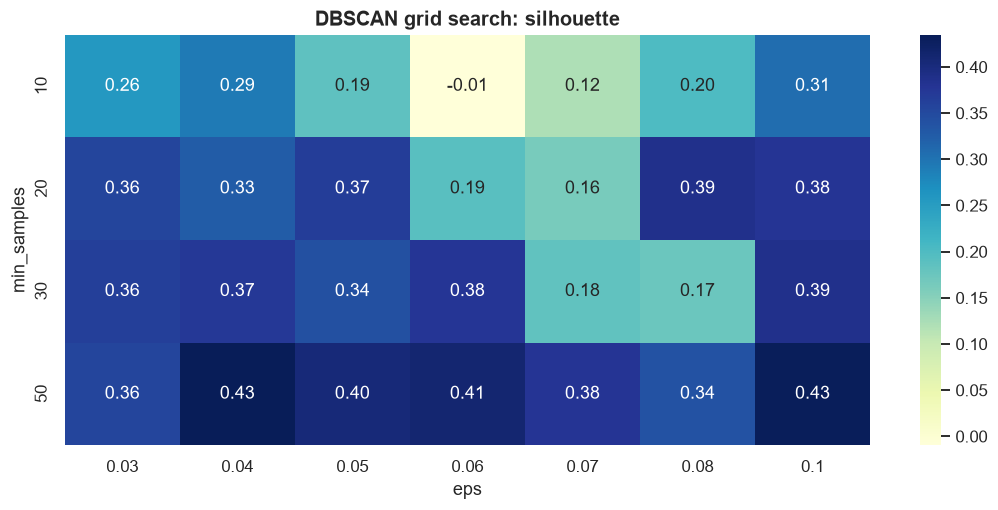

In [9]:
fig, path = viz.plot_dbscan_grid_heatmap(grid_geo, metric="n_clusters",
                                         name="dbscan_grid_clusters")
print("saved:", path)
plt.show()

fig, path = viz.plot_dbscan_grid_heatmap(grid_geo, metric="silhouette",
                                         name="dbscan_grid_silhouette")
print("saved:", path)
plt.show()

### Choosing the parameters

The k-distance knee is **≈ 0.038**. The grid shows the expected trade-off:

- `eps=0.03–0.04` → 40–62 micro-clusters and 5–12% noise, depending on
  `min_samples`: over-fragmentation.
- `eps=0.05, min_samples=30` → 30 clusters, 8.12% noise, silhouette 0.341.
- **`eps=0.06, min_samples=30` → 22 clusters, 6.07% noise, silhouette 0.377.**
- `eps=0.08, min_samples=20` → 11 clusters, 3.17% noise: adjacent metros start
  chaining together.
- `eps=0.10, min_samples=20` → 6 clusters, 2.48% noise: Bay Area, Sacramento and
  the Central Valley merge into broad corridors.

`min_samples=30` is a deliberate definition of a hotspot: at least 30 block
groups (≈0.15% of the dataset) must lie in the same neighbourhood. It also makes
the result stable — raising it to 50 keeps 22 clusters with 9.93% noise.

In [10]:
EPS_GEO, MS_GEO = 0.06, 30
labels_db = cl.run_dbscan(ds_geo.X, eps=EPS_GEO, min_samples=MS_GEO)

summary_db = cl.label_summary(labels_db)
metrics_db = cl.evaluate_clustering(ds_geo.X, labels_db, sample_size=8000)
print("Cluster summary:", summary_db)
print("Metrics:", {key: round(value, 3) if isinstance(value, float) else value
                   for key, value in metrics_db.items()})

profile_db = cl.cluster_profile(ds_geo.df, labels_db)

results = ds_geo.df.copy()
results["dbscan_cluster"] = labels_db
results.to_csv(pp.OUTPUT_DIR / "dbscan_geo_labels.csv", index=False)
profile_db.to_csv(pp.OUTPUT_DIR / "dbscan_geo_profile.csv")
print("saved labels and profile to", pp.OUTPUT_DIR)

Cluster summary: {'n_clusters': 22, 'n_noise': 1252, 'noise_pct': 6.07, 'n_clustered_points': 19388}
Metrics: {'n_clusters': 22, 'n_noise': 1252, 'noise_pct': 6.07, 'n_clustered_points': 19388, 'silhouette': 0.377, 'davies_bouldin': 0.495, 'calinski_harabasz': 39605.023, 'silhouette_sample_size': 8000}
saved labels and profile to D:\proj\Real-Estate-Spatial-Price-Clustering\real-estate-clustering\outputs


In [11]:
profile_db[["n_points", "share_pct", "mean_house_value", "mean_income",
            "mean_latitude", "mean_longitude",
            "dominant_ocean_proximity"]].sort_values(
    "mean_house_value", ascending=False).round(2)

,n_points,share_pct,mean_house_value,mean_income,mean_latitude,mean_longitude,dominant_ocean_proximity
cluster,,,,,,,
17,162,0.78,330036.56,4.26,34.42,-119.72,NEAR OCEAN
0,4749,23.01,264124.25,4.48,37.67,-122.18,NEAR BAY
10,8862,42.94,230500.55,4.08,33.99,-118.10,<1H OCEAN
15,1586,7.68,197395.93,3.79,32.85,-117.12,NEAR OCEAN
16,218,1.06,183841.29,3.39,35.01,-120.53,<1H OCEAN
13,31,0.15,164300.00,3.47,39.23,-120.11,INLAND
4,26,0.13,156142.31,3.47,38.72,-120.85,INLAND
21,50,0.24,156018.00,3.21,38.62,-121.77,INLAND
11,102,0.49,144751.96,3.76,34.65,-118.13,INLAND


## Visualising the DBSCAN hotspots

In [12]:
noise_mask = labels_db == -1
noise_values = ds_geo.df.loc[noise_mask, "median_house_value"]

print(f"noise points: {noise_mask.sum():,} ({noise_mask.mean() * 100:.2f}%)")
print(f"noise mean house value: ${noise_values.mean():,.0f}")
print(f"noise share >= $400k: {(noise_values >= 400_000).mean() * 100:.2f}%")
print(f"overall share >= $400k: {(ds_geo.df['median_house_value'] >= 400_000).mean() * 100:.2f}%")

clustered = profile_db.loc[profile_db.index != -1]
print("cluster-level income/value correlation:",
      round(clustered["mean_income"].corr(clustered["mean_house_value"]), 3))

noise points: 1,252 (6.07%)
noise mean house value: $110,920
noise share >= $400k: 1.04%
overall share >= $400k: 8.58%
cluster-level income/value correlation: 0.909


saved: D:\proj\Real-Estate-Spatial-Price-Clustering\real-estate-clustering\outputs\visualizations\dbscan_clusters.png


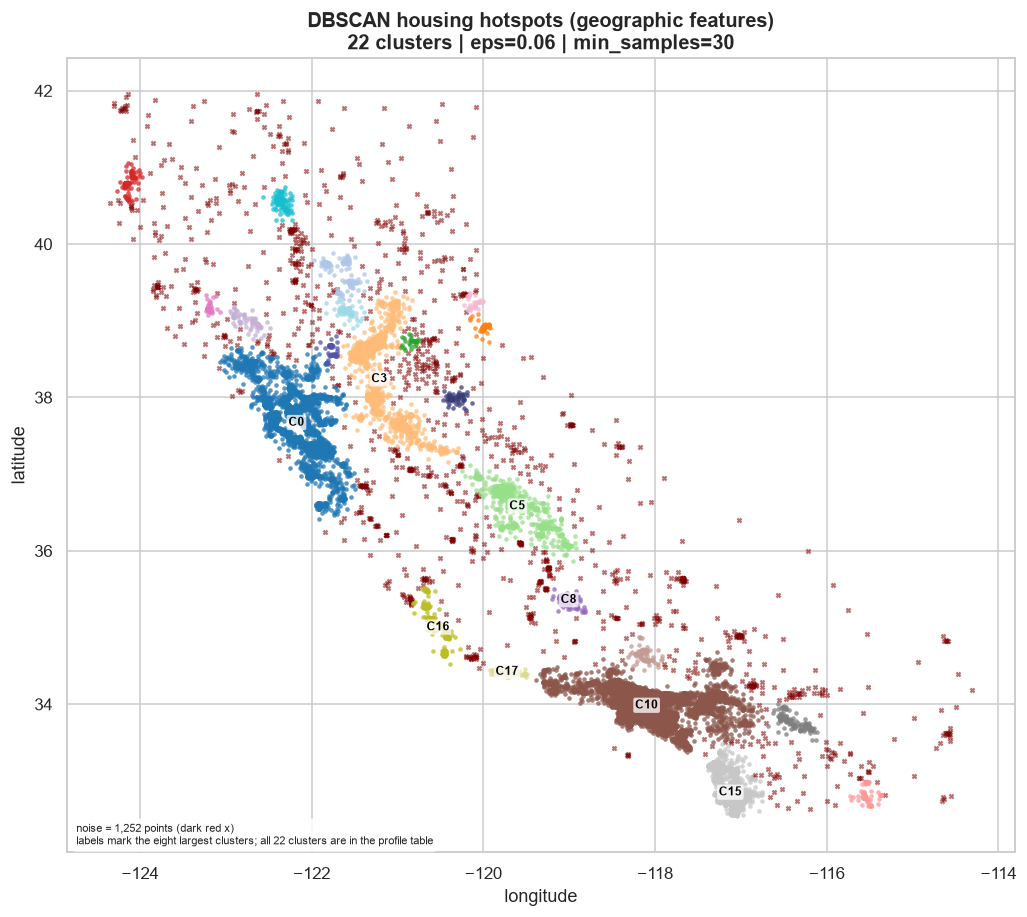

saved: D:\proj\Real-Estate-Spatial-Price-Clustering\real-estate-clustering\outputs\visualizations\dbscan_avg_value.png


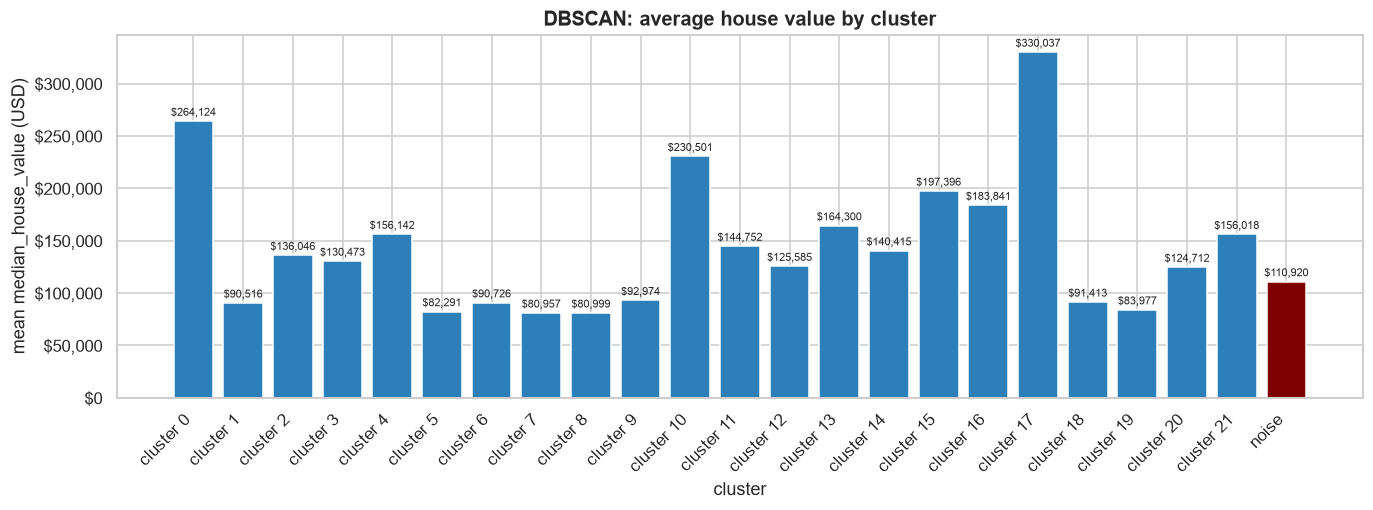

saved: D:\proj\Real-Estate-Spatial-Price-Clustering\real-estate-clustering\outputs\visualizations\dbscan_cluster_sizes.png


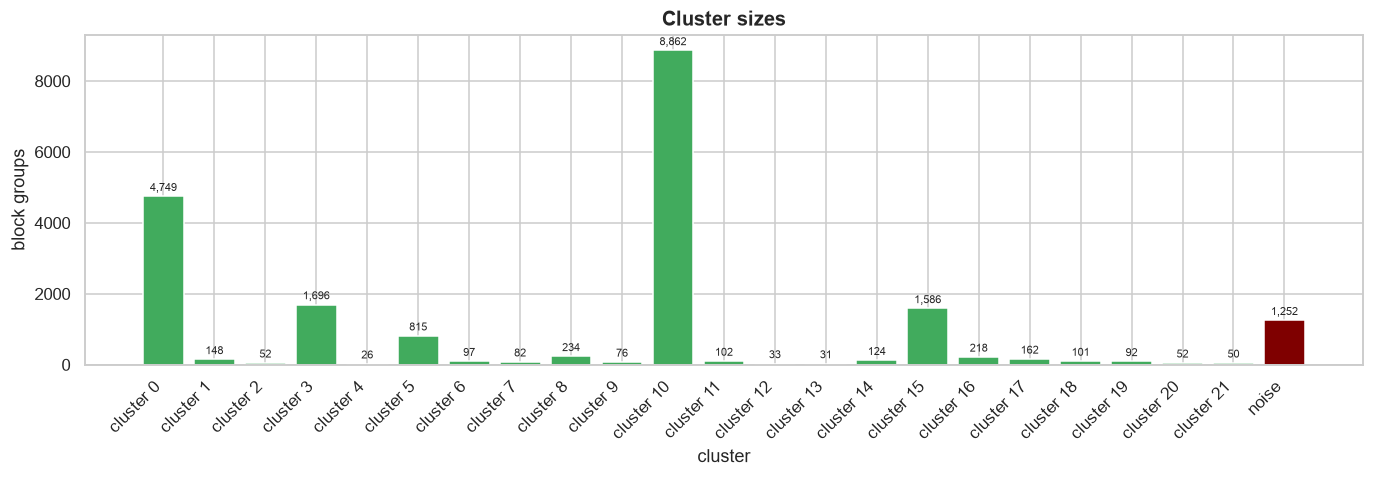

In [13]:
fig, path = viz.plot_dbscan_clusters(
    ds_geo.df, labels_db, eps=EPS_GEO, min_samples=MS_GEO,
    title="DBSCAN housing hotspots (geographic features)",
    name="dbscan_clusters",
)
print("saved:", path)
plt.show()

fig, path = viz.plot_avg_value_by_cluster(
    profile_db, title="DBSCAN: average house value by cluster",
    name="dbscan_avg_value",
)
print("saved:", path)
plt.show()

fig, path = viz.plot_cluster_sizes(profile_db, name="dbscan_cluster_sizes")
print("saved:", path)
plt.show()

In [14]:
map_path = viz.build_cluster_map(
    ds_geo.df, labels_db,
    title="DBSCAN housing hotspots",
    filename="dbscan_clusters.html",
)
noise_path = viz.build_noise_map(ds_geo.df, labels_db, filename="dbscan_noise.html")
plotly_path = viz.save_plotly_cluster_scatter(
    ds_geo.df, labels_db,
    title="DBSCAN housing hotspots (interactive)",
    filename="dbscan_clusters_interactive.html",
)
scatter_path = viz.save_plotly_cluster_scatter_2d(
    ds_geo.df, labels_db,
    title="DBSCAN clusters in feature space (income vs value)",
    filename="dbscan_clusters_scatter.html",
)

print("folium cluster map:", map_path)
print("folium noise map:  ", noise_path)
print("plotly map:        ", plotly_path)
print("plotly scatter:    ", scatter_path)

folium cluster map: D:\proj\Real-Estate-Spatial-Price-Clustering\real-estate-clustering\outputs\maps\dbscan_clusters.html
folium noise map:   D:\proj\Real-Estate-Spatial-Price-Clustering\real-estate-clustering\outputs\maps\dbscan_noise.html
plotly map:         D:\proj\Real-Estate-Spatial-Price-Clustering\real-estate-clustering\outputs\visualizations\dbscan_clusters_interactive.html
plotly scatter:     D:\proj\Real-Estate-Spatial-Price-Clustering\real-estate-clustering\outputs\visualizations\dbscan_clusters_scatter.html


## Interpreting the hotspots

The four largest clusters account for **82%** of all block groups:

| cluster | location | block groups | mean value | mean income |
|---|---|---:|---:|---:|
| 10 | Los Angeles / Southern California coast (33.99, −118.10) | 8,862 | \$230,501 | 4.08 |
| 0 | San Francisco Bay Area (37.67, −122.18) | 4,749 | \$264,124 | 4.48 |
| 3 | Sacramento / northern Central Valley (38.24, −121.21) | 1,696 | \$130,473 | 3.25 |
| 15 | San Diego (32.85, −117.12) | 1,586 | \$197,396 | 3.79 |

Smaller but distinct dense pockets include the Central Valley around Fresno
(cluster 5: 815 block groups, mean \$82,291), Bakersfield (cluster 8: 234 block
groups, mean \$80,999), the Santa Barbara coast (cluster 17: 162 block groups,
mean **\$330,037** — the most expensive cluster), and the far northern coast near
Eureka (cluster 6: 97 block groups, mean \$90,726).

**Noise** contains 1,252 block groups (6.07%). Its mean value is **\$110,920**,
and only **1.04%** of noise points are ≥ \$400k, compared with **8.58%** of the
whole dataset. DBSCAN's noise is therefore mostly isolated, low-density inland
locations — not hidden luxury enclaves.

Across the 22 clusters, mean income and mean house value correlate at
**r ≈ 0.91** (unweighted cluster means), confirming that the expensive hotspots
are also the high-income hotspots.

One caveat visible on the map: the Bay Area cluster chains down the peninsula and
into neighbouring dense areas, while Los Angeles absorbs most of the southern
coast. DBSCAN follows *density connectivity*, so a continuous urban corridor
becomes one cluster even when it contains distinct sub-markets.

## DBSCAN findings

- **22 clusters**, **1,252 noise points (6.07%)**, mean cluster size 881.
- Silhouette **0.377** on the clustered points (noise excluded), Davies–Bouldin
  **0.495**, Calinski–Harabasz **39,605** on the 2-D geo matrix.
- Runtime: **≈0.3 s** for 20,640 points.
- Clear coastal/inland divide: Bay Area and LA/San Diego are dense and
  expensive; the Central Valley is dense but cheap; mountain/desert locations
  are mostly noise.
- The same algorithm on the 11-D matrix collapses into one dominant cluster
  (98.63%) — feature-space design matters more than parameter tuning for DBSCAN.